Loaded rows: 2749


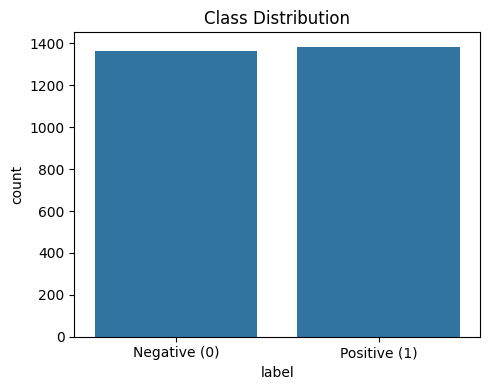

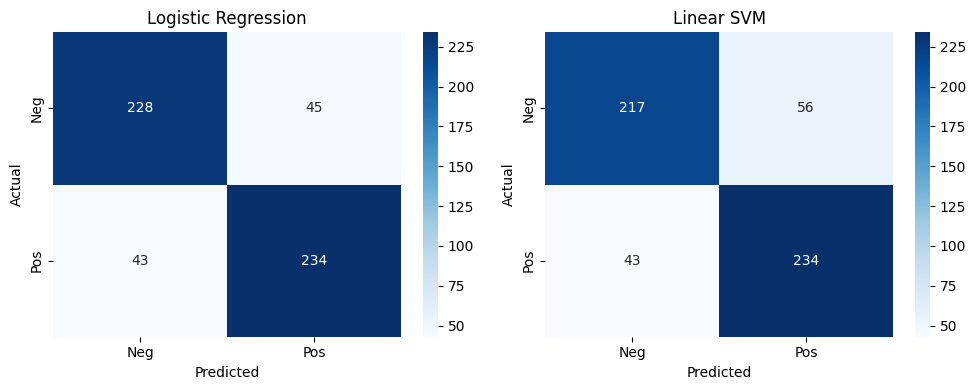

I really loved this movie, it was great!  -->  LR: Pos | SVM: Pos
The food was cold and service was bad.  -->  LR: Neg | SVM: Neg
This phone has an amazing camera.  -->  LR: Pos | SVM: Pos
I would not recommend this to anyone.  -->  LR: Neg | SVM: Neg


In [3]:
import os
import re
import urllib.request
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

# 1. Dataset zip එක download කරලා extract කිරීම
zip_url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
zip_path = "sentiment_data.zip"
extract_dir = "sentiment_extracted"

urllib.request.urlretrieve(zip_url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zf:
  zf.extractall(extract_dir)

# Extract වුණු folder එක ඇතුළෙන් .txt files 3 හොයාගැනීම
file_list = []
for root, _, files in os.walk(extract_dir):
  for f in files:
    if f.endswith(".txt") and (
        "amazon" in f.lower() or "imdb" in f.lower() or "yelp" in f.lower()
    ):
      src_name = (
          "amazon"
          if "amazon" in f.lower()
          else ("imdb" if "imdb" in f.lower() else "yelp")
      )
      file_list.append((os.path.join(root, f), src_name))

part_dfs = []
for fpath, source in file_list:
  temp = pd.read_csv(
      fpath, sep="\t", header=None, names=["text", "label"], encoding="utf-8"
  )
  temp["source"] = source
  part_dfs.append(temp)

data = pd.concat(part_dfs, ignore_index=True)
print("Loaded rows:", len(data))

# 2. Text preprocessing
re_non_alpha = re.compile(r"[^a-z\s]")
re_multi_space = re.compile(r"\s+")


def clean_text(raw):
  if pd.isna(raw):
    return ""
  txt = str(raw).lower()
  txt = re_non_alpha.sub(" ", txt)
  txt = re_multi_space.sub(" ", txt).strip()
  return txt


data["clean_text"] = data["text"].apply(clean_text)
valid_rows = data["clean_text"].str.len() > 0
data = data[valid_rows].reset_index(drop=True)

# 3. Class distribution graph එක පෙන්වීම
plt.figure(figsize=(5, 4))
sns.countplot(data=data, x="label")
plt.xticks([0, 1], ["Negative (0)", "Positive (1)"])
plt.title("Class Distribution")
plt.tight_layout()
plt.show()

# 4. Train / Test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    data["clean_text"],
    data["label"],
    test_size=0.2,
    random_state=42,
    stratify=data["label"],
)

# 5. Bag-of-Words representation
bow = CountVectorizer()
X_train_vec = bow.fit_transform(X_train)
X_test_vec = bow.transform(X_test)

# 6 & 7. Train & Evaluate Models
clf_lr = LogisticRegression(max_iter=1000, random_state=42)
clf_svm = LinearSVC(random_state=42)

clf_lr.fit(X_train_vec, y_train)
clf_svm.fit(X_train_vec, y_train)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for idx, (name, model) in enumerate(
    [("Logistic Regression", clf_lr), ("Linear SVM", clf_svm)]
):
  y_pred = model.predict(X_test_vec)
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      ax=axes[idx],
      xticklabels=["Neg", "Pos"],
      yticklabels=["Neg", "Pos"],
  )
  axes[idx].set_title(name)
  axes[idx].set_xlabel("Predicted")
  axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# 8. Test new sentences
test_cases = [
    "I really loved this movie, it was great!",
    "The food was cold and service was bad.",
    "This phone has an amazing camera.",
    "I would not recommend this to anyone.",
]

vec_new = bow.transform([clean_text(s) for s in test_cases])
pred_lr = clf_lr.predict(vec_new)
pred_svm = clf_svm.predict(vec_new)

for sent, p1, p2 in zip(test_cases, pred_lr, pred_svm):
  print(
      f"{sent}  -->  LR: {'Pos' if p1==1 else 'Neg'} | SVM:"
      f" {'Pos' if p2==1 else 'Neg'}"
  )

In [4]:
for name, model in [
    ("Logistic Regression", clf_lr),
    ("Linear SVM", clf_svm),
]:
  y_pred = model.predict(X_test_vec)
  print(f"=== {name} ===")
  print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
  print("Precision:", round(precision_score(y_test, y_pred), 4))
  print("Recall   :", round(recall_score(y_test, y_pred), 4))
  print("F1 Score :", round(f1_score(y_test, y_pred), 4))

=== Logistic Regression ===
Accuracy : 0.84
Precision: 0.8387
Recall   : 0.8448
F1 Score : 0.8417
=== Linear SVM ===
Accuracy : 0.82
Precision: 0.8069
Recall   : 0.8448
F1 Score : 0.8254
